In [1]:
# =============================================================================
# PREPROCESAMIENTO DEL DOW JONES - Reto 9 (BBVA, call asiática)
#
# Datasets de entrada:
#   - Datos/Originales/DowJones/*_marketstack.csv  -> 26 CSV intradía (uno por empresa)
#   - Yahoo Finance (descarga con yfinance)         -> histórico diario 2016-2025
# Datasets de salida:
#   - Datos/Transformados/dowjones_diario_2016_2025.csv -> dataset limpio e imputado (CSV + Yahoo)
# =============================================================================
import glob
import os

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf

RUTA_ORIGINALES = "Datos/Originales/DowJones/*.csv"
RUTA_TRANSFORMADOS = "Datos/Transformados"
FECHA_INICIO = "2016-01-01"
FECHA_FIN = "2026-01-01"      # extremo exclusivo en yfinance -> último día incluido 2025-12-31
HORA_CIERRE = 16 * 60         # cierre de la sesión regular de Nueva York (16:00), en minutos
UMBRAL_VOLUMEN = 0.5          # volumen del CSV por debajo del 50 % del de Yahoo -> no es el consolidado

C:\Users\Personal\.conda\envs\BDA\Lib\site-packages\requests\__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


In [2]:
# =============================================================================
# 1. Carga y unificación de los 26 CSV + primera exploración
# =============================================================================
archivos = sorted(glob.glob(RUTA_ORIGINALES))
df = pd.concat([pd.read_csv(f) for f in archivos], ignore_index=True)
df["date"] = pd.to_datetime(df["date"])          # la fecha, lo primero
empresas = sorted(df["symbol"].unique())

print(f"{len(archivos)} ficheros | {len(empresas)} empresas | {len(df):,} filas")
print(empresas)
print(df.dtypes)

# Missings en contexto: número y porcentaje sobre el total de filas
print(pd.DataFrame({"nulos": df.isna().sum(), "pct": (df.isna().mean() * 100).round(2)}))
print("Duplicados exactos:", df.duplicated().sum(), "| Duplicados symbol+date:", df.duplicated(subset=["symbol", "date"]).sum())
print("Precios <= 0:", int((df[["open", "high", "low", "close", "last"]] <= 0).sum().sum()),
      "| Volumen negativo:", int((df["volume"] < 0).sum()))
print(df.groupby("symbol")["date"].agg(["min", "max", "count"]))

26 ficheros | 26 empresas | 2,744,418 filas
['AAPL', 'AMGN', 'AXP', 'BA', 'CAT', 'CRM', 'CSCO', 'CVX', 'DIS', 'DOW', 'GS', 'HD', 'IBM', 'INTC', 'JNJ', 'JPM', 'KO', 'MCD', 'MMM', 'MRK', 'MSFT', 'NKE', 'PG', 'TRV', 'UNH', 'V']
open                    float64
high                    float64
low                     float64
last                    float64
close                   float64
volume                  float64
date        datetime64[us, UTC]
symbol                      str
exchange                    str
dtype: object


           nulos    pct
open           0   0.00
high           0   0.00
low            0   0.00
last      849956  30.97
close     611651  22.29
volume    847408  30.88
date           0   0.00
symbol         0   0.00
exchange       0   0.00


Duplicados exactos: 0 | Duplicados symbol+date: 0
Precios <= 0: 0 | Volumen negativo: 0


                             min                       max   count
symbol                                                            
AAPL   2018-06-06 17:30:00+00:00 2021-07-01 00:00:00+00:00   48723
AMGN   2020-05-29 15:35:00+00:00 2021-07-01 00:00:00+00:00   25296
AXP    2020-05-29 15:30:59+00:00 2021-07-01 00:00:00+00:00   95650
BA     2020-05-29 15:35:51+00:00 2021-07-01 00:00:00+00:00  101436
CAT    2018-06-11 17:30:00+00:00 2021-07-01 00:00:00+00:00  122364
CRM    2020-05-29 15:31:30+00:00 2021-07-01 00:00:00+00:00  108823
CSCO   2020-05-29 15:31:26+00:00 2021-07-01 00:00:00+00:00  108585
CVX    2020-05-29 15:31:23+00:00 2021-07-01 00:00:00+00:00  108876
DIS    2020-05-29 15:35:00+00:00 2021-07-01 00:00:00+00:00  109393
DOW    2020-05-29 15:35:56+00:00 2021-07-01 00:00:00+00:00  106437
GS     2018-06-11 17:30:00+00:00 2021-07-01 00:00:00+00:00  133145
HD     2020-05-29 17:55:51+00:00 2021-07-01 00:00:00+00:00  105219
IBM    2020-05-29 17:56:29+00:00 2021-07-01 00:00:00+00:00  10

In [3]:
# =============================================================================
# 2. Hora de Nueva York: la sesión y los días de mercado se definen allí, no en UTC
# =============================================================================
df["hora_ny"] = df["date"].dt.tz_convert("America/New_York")
df["dia_ny"] = df["hora_ny"].dt.tz_localize(None).dt.normalize()
df["minuto_ny"] = df["hora_ny"].dt.hour * 60 + df["hora_ny"].dt.minute
df = df.sort_values(["symbol", "date"]).reset_index(drop=True)

dia_utc = df["date"].dt.tz_localize(None).dt.normalize()
print("Filas que caen en fin de semana agrupando por día UTC:", int((dia_utc.dt.dayofweek >= 5).sum()))
print("Filas que caen en fin de semana agrupando por día NY: ", int((df["dia_ny"].dt.dayofweek >= 5).sum()))

Filas que caen en fin de semana agrupando por día UTC: 13702
Filas que caen en fin de semana agrupando por día NY:  0


In [4]:
# =============================================================================
# 3. Qué significa cada columna del CSV
# =============================================================================
fuera_rango = (df["close"] > df["high"]) | (df["close"] < df["low"])
print(f"Filas con close fuera de [low, high]: {fuera_rango.sum():,} de {len(df):,} ({fuera_rango.mean():.1%})")

# Ejemplo: CRM publicó resultados el 25/08/2020 tras el cierre y el 26/08 subió un 26 %
crm = df[(df["symbol"] == "CRM") & (df["dia_ny"] == "2020-08-26")]
print("\nCRM 26/08/2020 (una fila de cada 60):")
print(crm[["hora_ny", "open", "high", "low", "last", "close", "volume"]].iloc[::60].to_string())

# Final del 25/08: sesión regular hasta las 16:00, después after-hours
crm_25 = df[(df["symbol"] == "CRM") & (df["dia_ny"] == "2020-08-25") & (df["minuto_ny"] >= 15 * 60 + 55)]
print("\nCRM 25/08/2020 desde las 15:55:")
print(crm_25[["hora_ny", "last", "close"]].to_string())

# ¿El volumen es acumulado dentro del día? (se comprueba en todo el dataset, no solo en el ejemplo)
variacion = df.dropna(subset=["volume"]).groupby(["symbol", "dia_ny"])["volume"].diff().dropna()
print(f"\nMinutos consecutivos en los que el volumen crece o se mantiene: {(variacion >= 0).mean():.2%}")

# Tramo antiguo (sin last): close sí se mueve dentro del día (ej. AAPL, 13/03/2020)
aapl_antiguo = df[(df["symbol"] == "AAPL") & (df["dia_ny"] == "2020-03-13")]
print("\nAAPL 13/03/2020 (tramo sin last):", aapl_antiguo["close"].nunique(), "valores distintos de close en",
      len(aapl_antiguo), "barras")

Filas con close fuera de [low, high]: 761,432 de 2,744,418 (27.7%)


CRM 26/08/2020 (una fila de cada 60):
                         hora_ny    open    high     low     last   close     volume
410616 2020-08-26 08:52:00-04:00  249.29  249.29  246.78  246.780  216.05     4599.0
410676 2020-08-26 10:32:00-04:00  249.29  276.14  246.78  272.325  216.05   580805.0
410736 2020-08-26 11:47:00-04:00  249.29  277.79  246.78  271.130  216.05  1171892.0
410796 2020-08-26 13:09:00-04:00  249.29  277.79  246.78  274.185  216.05  1401530.0
410856 2020-08-26 14:25:00-04:00  249.29  277.79  246.78  271.675  216.05  1596052.0
410916 2020-08-26 15:42:00-04:00  249.29  277.79  246.78  269.630  216.05  1738652.0

CRM 25/08/2020 desde las 15:55:
                         hora_ny     last   close
410603 2020-08-25 15:56:00-04:00  216.370  208.46
410604 2020-08-25 15:57:00-04:00  216.190  208.46
410605 2020-08-25 15:58:00-04:00  216.120  208.46
410606 2020-08-25 15:59:00-04:00  216.100  208.46
410607 2020-08-25 16:05:00-04:00  223.000  208.46
410608 2020-08-25 16:11:00-04:00 


Minutos consecutivos en los que el volumen crece o se mantiene: 99.98%

AAPL 13/03/2020 (tramo sin last): 37 valores distintos de close en 79 barras


In [5]:
# =============================================================================
# 4. Agregación a frecuencia diaria
#    close: último last hasta las 16:00 NY; si el día no tiene last, último close
# =============================================================================
df["last_sesion"] = df["last"].where(df["minuto_ny"] <= HORA_CIERRE)

diario = (
    df.groupby(["symbol", "dia_ny"], as_index=False)
    .agg(
        open=("open", "first"),
        high=("high", "max"),
        low=("low", "min"),
        last_sesion=("last_sesion", "last"),   # último last de la sesión regular
        last_dia=("last", "last"),             # respaldo si no hay last antes de las 16:00
        close_barra=("close", "last"),         # solo válido en el tramo sin last
        n_last=("last", "count"),
        volume=("volume", "max"),              # volumen acumulado -> el máximo es el total del día
    )
    .rename(columns={"dia_ny": "date"})
)
diario["close"] = np.where(
    diario["n_last"] > 0,
    diario["last_sesion"].fillna(diario["last_dia"]),
    diario["close_barra"],
)
diario = diario[["symbol", "date", "open", "high", "low", "close", "volume"]]

print(diario.shape)
print(f"Días sin cierre: {diario['close'].isna().sum()} de {len(diario)}")
print(diario.loc[diario["close"].isna(), "date"].dt.date.value_counts())
print(f"Días sin volumen: {diario['volume'].isna().sum()} de {len(diario)}")
print(diario[(diario["symbol"] == "CRM") & diario["date"].between("2020-08-24", "2020-08-27")].to_string())

(10177, 7)
Días sin cierre: 94 de 10177
date
2021-03-11    26
2021-03-12    26
2021-03-30    26
2021-03-31    16
Name: count, dtype: int64
Días sin volumen: 3272 de 10177
     symbol       date     open    high     low   close      volume
2456    CRM 2020-08-24  209.105  209.29  205.15  208.50   5093688.0
2457    CRM 2020-08-25  213.500  241.42  210.80  216.10  23880535.0
2458    CRM 2020-08-26  249.290  277.97  246.78  273.41  62557558.0
2459    CRM 2020-08-27  267.600  278.28  260.84  278.13  22710092.0


In [6]:
# =============================================================================
# 5. Descarga de Yahoo Finance (2016-2025) para las mismas 26 empresas
# =============================================================================
partes, splits, fallidos = [], {}, []
for ticker in empresas:
    try:
        activo = yf.Ticker(ticker)
        hist = activo.history(start=FECHA_INICIO, end=FECHA_FIN, auto_adjust=False)
        if hist.empty:
            fallidos.append(ticker)
            continue
        hist = hist.reset_index()[["Date", "Open", "High", "Low", "Close", "Volume"]]
        hist.columns = ["date", "open", "high", "low", "close", "volume"]
        hist["date"] = pd.to_datetime(hist["date"]).dt.tz_localize(None).dt.normalize()
        hist["symbol"] = ticker
        partes.append(hist)

        # Eventos de split (y spin-offs, que Yahoo registra como split) dentro de la ventana
        eventos = activo.splits
        eventos.index = eventos.index.tz_localize(None).normalize()
        splits[ticker] = eventos[(eventos.index >= FECHA_INICIO) & (eventos.index < FECHA_FIN)]
    except Exception as error:
        fallidos.append(ticker)
        print(f"{ticker}: falló la descarga -> {error}")

yahoo = pd.concat(partes, ignore_index=True)
print("Descargadas:", yahoo["symbol"].nunique(), "de", len(empresas), "| Fallidas:", fallidos)
print(yahoo.groupby("symbol")["date"].agg(["min", "max", "count"]))

Descargadas: 26 de 26 | Fallidas: []
              min        max  count
symbol                             
AAPL   2016-01-04 2025-12-31   2514
AMGN   2016-01-04 2025-12-31   2514
AXP    2016-01-04 2025-12-31   2514
BA     2016-01-04 2025-12-31   2514
CAT    2016-01-04 2025-12-31   2514
CRM    2016-01-04 2025-12-31   2514
CSCO   2016-01-04 2025-12-31   2514
CVX    2016-01-04 2025-12-31   2514
DIS    2016-01-04 2025-12-31   2514
DOW    2019-03-20 2025-12-31   1707
GS     2016-01-04 2025-12-31   2514
HD     2016-01-04 2025-12-31   2514
IBM    2016-01-04 2025-12-31   2514
INTC   2016-01-04 2025-12-31   2514
JNJ    2016-01-04 2025-12-31   2514
JPM    2016-01-04 2025-12-31   2514
KO     2016-01-04 2025-12-31   2514
MCD    2016-01-04 2025-12-31   2514
MMM    2016-01-04 2025-12-31   2514
MRK    2016-01-04 2025-12-31   2514
MSFT   2016-01-04 2025-12-31   2514
NKE    2016-01-04 2025-12-31   2514
PG     2016-01-04 2025-12-31   2514
TRV    2016-01-04 2025-12-31   2514
UNH    2016-01-04 2025-12-3

Eventos que Yahoo registra como split:
  AAPL  2020-08-31  factor 4
  IBM   2021-11-04  factor 1.046
  MMM   2024-04-01  factor 1.196
  MRK   2021-06-03  factor 1.048


               dias  cociente_close  cociente_volume
symbol factor                                       
AAPL   1.000    206           1.000            0.985
       4.000    562           4.000            0.246
IBM    1.046    268           1.046            0.956
MMM    1.196    267           1.196            0.836
MRK    1.000     20           1.000            0.035
       1.048    248           1.048            0.954


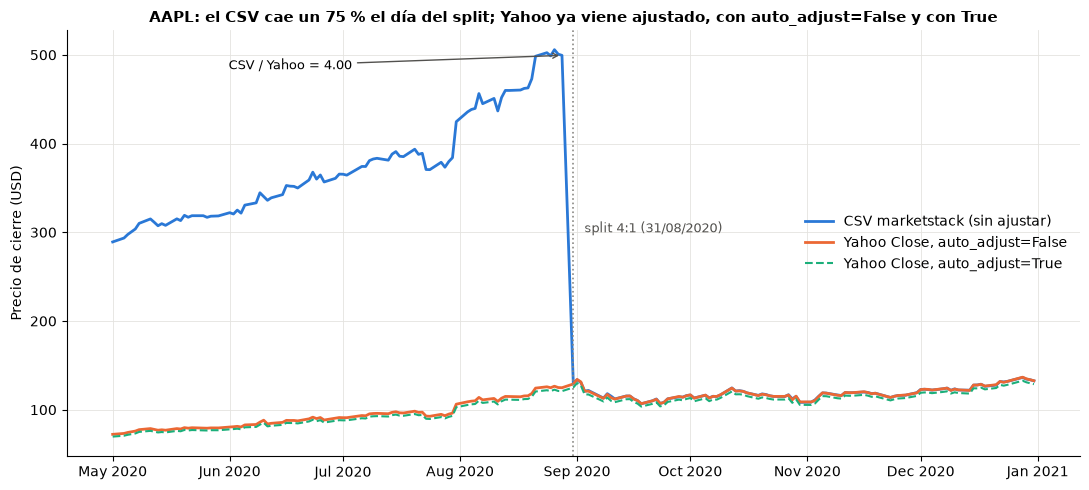

In [7]:
# =============================================================================
# 6. Splits: ¿qué fuente viene ajustada?
# =============================================================================
def factor_split(ticker, fecha):
    """Producto de los factores de split posteriores a la fecha (1 si no hay ninguno)."""
    eventos = splits.get(ticker)
    if eventos is None or eventos.empty:
        return 1.0
    posteriores = eventos[eventos.index > fecha]
    return float(np.prod(posteriores.values)) if len(posteriores) else 1.0


print("Eventos que Yahoo registra como split:")
for ticker, eventos in splits.items():
    for fecha, ratio in eventos.items():
        print(f"  {ticker:5s} {fecha.date()}  factor {ratio:g}")

# Si Yahoo está ajustado y el CSV no, close_CSV / close_Yahoo = factor de split posterior
comparacion = diario.merge(
    yahoo[["symbol", "date", "close", "volume"]].rename(columns={"close": "close_yahoo", "volume": "volume_yahoo"}),
    on=["symbol", "date"], how="inner",
).dropna(subset=["close"])
comparacion["factor"] = [factor_split(t, f) for t, f in zip(comparacion["symbol"], comparacion["date"])]
comparacion["cociente_close"] = comparacion["close"] / comparacion["close_yahoo"]
comparacion["cociente_volume"] = comparacion["volume"] / comparacion["volume_yahoo"]

con_eventos = [t for t, ev in splits.items() if not ev.empty]
print(
    comparacion[comparacion["symbol"].isin(con_eventos)]
    .groupby(["symbol", "factor"])
    .agg(dias=("cociente_close", "size"),
         cociente_close=("cociente_close", "median"),
         cociente_volume=("cociente_volume", "median"))
    .round(3)
)

# Gráfica: AAPL alrededor del split 4:1 del 31/08/2020, CSV frente a Yahoo con y sin auto_adjust
FECHA_SPLIT_AAPL = pd.Timestamp("2020-08-31")
aapl_csv = diario[diario["symbol"] == "AAPL"].set_index("date")["close"].loc["2020-05-01":"2020-12-31"]
aapl_sin_auto = yf.Ticker("AAPL").history(start="2020-05-01", end="2021-01-01", auto_adjust=False)["Close"]
aapl_con_auto = yf.Ticker("AAPL").history(start="2020-05-01", end="2021-01-01", auto_adjust=True)["Close"]
for serie in (aapl_sin_auto, aapl_con_auto):
    serie.index = serie.index.tz_localize(None).normalize()

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(aapl_csv, color="#2a78d6", lw=2, label="CSV marketstack (sin ajustar)")
ax.plot(aapl_sin_auto, color="#eb6834", lw=2, label="Yahoo Close, auto_adjust=False")
ax.plot(aapl_con_auto, color="#1baf7a", lw=1.5, ls="--", label="Yahoo Close, auto_adjust=True")
ax.axvline(FECHA_SPLIT_AAPL, color="#8a8984", ls=":", lw=1.2)
ax.annotate("split 4:1 (31/08/2020)", xy=(FECHA_SPLIT_AAPL, 300), xytext=(8, 0),
            textcoords="offset points", color="#52514e", fontsize=9)
dia_antes = aapl_csv.loc[:FECHA_SPLIT_AAPL - pd.Timedelta(days=1)].index.max()
ax.annotate(f"CSV / Yahoo = {aapl_csv[dia_antes] / aapl_sin_auto[dia_antes]:.2f}",
            xy=(dia_antes, aapl_csv[dia_antes]), xytext=(-240, -10), textcoords="offset points",
            arrowprops=dict(arrowstyle="->", color="#52514e"), fontsize=9)
ax.set_title("AAPL: el CSV cae un 75 % el día del split; Yahoo ya viene ajustado, con auto_adjust=False y con True",
             fontsize=11, fontweight="bold")
ax.set_ylabel("Precio de cierre (USD)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.spines[["top", "right"]].set_visible(False)
ax.grid(color="#e4e3df", lw=0.6)
ax.legend(loc="center right", frameon=False)
plt.tight_layout()
plt.show()

In [8]:
# =============================================================================
# 7. Ajuste del CSV a la escala de Yahoo: precios / factor, volumen * factor
# =============================================================================
diario["factor"] = [factor_split(t, f) for t, f in zip(diario["symbol"], diario["date"])]
for col in ["open", "high", "low", "close"]:
    diario[col] = diario[col] / diario["factor"]
diario["volume"] = diario["volume"] * diario["factor"]
print("Filas del CSV ajustadas:", int((diario["factor"] != 1).sum()))
print(diario.loc[diario["factor"] != 1].groupby("symbol")["factor"].agg(["min", "max", "count"]))
diario = diario.drop(columns=["factor"])

# Validación del cierre contra Yahoo en los días comunes (no se usa para sustituir: el CSV manda)
validacion = diario.merge(
    yahoo[["symbol", "date", "close"]].rename(columns={"close": "close_yahoo"}),
    on=["symbol", "date"], how="inner",
).dropna(subset=["close"])
validacion["error_pct"] = (validacion["close"] / validacion["close_yahoo"] - 1).abs() * 100
print(f"\nDías comparados: {len(validacion)} | error medio {validacion['error_pct'].mean():.3f} % "
      f"| mediana {validacion['error_pct'].median():.3f} % | p99 {validacion['error_pct'].quantile(0.99):.3f} %")
print(f"Días con error > 1 %: {(validacion['error_pct'] > 1).sum()} | > 2 %: {(validacion['error_pct'] > 2).sum()} "
      f"| > 5 %: {(validacion['error_pct'] > 5).sum()}")
print(validacion.nlargest(5, "error_pct")[["symbol", "date", "close", "close_yahoo", "error_pct"]].round(3).to_string())

Filas del CSV ajustadas: 1374
          min    max  count
symbol                     
AAPL    4.000  4.000    581
IBM     1.046  1.046    271
MMM     1.196  1.196    271
MRK     1.048  1.048    251

Días comparados: 9969 | error medio 0.079 % | mediana 0.039 % | p99 0.591 %
Días con error > 1 %: 48 | > 2 %: 10 | > 5 %: 0
     symbol       date   close  close_yahoo  error_pct
5484   INTC 2020-03-18  49.770        47.61      4.537
5385   INTC 2019-10-24  54.330        52.23      4.021
2633   CSCO 2020-05-29  46.035        47.82      3.733
5446   INTC 2020-01-23  65.450        63.32      3.364
3651    DOW 2021-03-17  64.130        66.01      2.848


C:\Users\Personal\AppData\Local\Temp\ipykernel_13744\4090130531.py:22: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(validacion.nlargest(5, "error_pct")[["symbol", "date", "close", "close_yahoo", "error_pct"]].round(3).to_string())


In [9]:
# =============================================================================
# 8. Volumen: desde marzo de 2021 el CSV da solo el volumen de IEX
# =============================================================================
vol = diario.dropna(subset=["volume"]).merge(
    yahoo[["symbol", "date", "volume"]].rename(columns={"volume": "volume_yahoo"}),
    on=["symbol", "date"], how="inner",
)
vol["cociente"] = vol["volume"] / vol["volume_yahoo"]
print(vol.groupby(vol["date"].dt.to_period("M"))["cociente"].agg(["median", "min"]).round(3))
print("\nReparto del cociente CSV / Yahoo:")
print(pd.cut(vol["cociente"], [0, 0.1, 0.3, 0.5, 0.8, 1.2, np.inf]).value_counts().sort_index())

diario = diario.merge(
    yahoo[["symbol", "date", "volume"]].rename(columns={"volume": "volume_yahoo"}),
    on=["symbol", "date"], how="left",
)
volumen_iex = (diario["volume"] / diario["volume_yahoo"]) < UMBRAL_VOLUMEN
print(f"\nVolúmenes del CSV que no son el consolidado: {volumen_iex.sum()} de {diario['volume'].notna().sum()}")
diario.loc[volumen_iex, "volume"] = np.nan      # se imputan desde Yahoo en el paso 10
diario = diario.drop(columns=["volume_yahoo"])

         median    min
date                  
2020-05   1.000  1.000
2020-06   0.995  0.001
2020-07   1.000  0.010
2020-08   0.999  0.008
2020-09   1.000  0.005
2020-10   0.998  0.011
2020-11   1.000  0.017
2020-12   1.000  0.009
2021-01   1.000  0.023
2021-02   1.000  0.012
2021-03   0.039  0.000
2021-04   0.034  0.008
2021-05   0.033  0.010
2021-06   0.032  0.011

Reparto del cociente CSV / Yahoo:
cociente
(0.0, 0.1]    2211
(0.1, 0.3]       2
(0.3, 0.5]       0
(0.5, 0.8]      11
(0.8, 1.2]    4681
(1.2, inf]       0
Name: count, dtype: int64

Volúmenes del CSV que no son el consolidado: 2213 de 6905


In [10]:
# =============================================================================
# 9. Coherencia OHLC: high >= max(open, close) y low <= min(open, close)
# =============================================================================
def contar_incoherencias(d):
    d = d.dropna(subset=["close"])
    return int(((d["high"] < d[["open", "close"]].max(axis=1)) | (d["low"] > d[["open", "close"]].min(axis=1))).sum())


print("Velas incoherentes antes de reparar:", contar_incoherencias(diario), "de", diario["close"].notna().sum())
diario["high"] = diario[["high", "open", "close"]].max(axis=1)
diario["low"] = diario[["low", "open", "close"]].min(axis=1)
print("Velas incoherentes después de reparar:", contar_incoherencias(diario))

Velas incoherentes antes de reparar: 0 de 10083


Velas incoherentes después de reparar: 0


In [11]:
# =============================================================================
# 10. Combinación: el CSV manda, Yahoo imputa. Calendario = días de mercado de Yahoo
# =============================================================================
columnas = ["open", "high", "low", "close", "volume"]

# Filas del CSV en días sin mercado (festivos de la bolsa de EE. UU.)
festivos = diario.merge(yahoo[["symbol", "date"]], on=["symbol", "date"], how="left", indicator=True)
festivos = festivos[festivos["_merge"] == "left_only"]
print("Filas del CSV en días sin mercado (se eliminan):", len(festivos), "| empresas:", sorted(festivos["symbol"].unique()))
print(festivos["date"].dt.strftime("%Y-%m-%d %a").value_counts().head(6))

csv_valido = diario.dropna(subset=["close"])       # días sin cierre en el CSV -> fila entera de Yahoo
combinado = (
    yahoo[["symbol", "date"]]
    .merge(csv_valido[["symbol", "date"] + columnas], on=["symbol", "date"], how="left")
    .merge(yahoo[["symbol", "date"] + columnas], on=["symbol", "date"], how="left", suffixes=("", "_yahoo"))
)
combinado["fuente"] = np.where(combinado["close"].notna(), "csv", "yahoo")
combinado["volume_imputado"] = (combinado["fuente"] == "csv") & combinado["volume"].isna()
for col in columnas:
    combinado[col] = combinado[col].fillna(combinado[f"{col}_yahoo"])

df_final = (
    combinado[["symbol", "date"] + columnas + ["fuente", "volume_imputado"]]
    .sort_values(["symbol", "date"])
    .reset_index(drop=True)
)

Filas del CSV en días sin mercado (se eliminan): 114 | empresas: ['AAPL', 'CAT', 'GS', 'INTC', 'NKE', 'V']
date
2018-07-04 Wed    6
2018-09-03 Mon    6
2018-11-22 Thu    6
2018-12-05 Wed    6
2018-12-25 Tue    6
2019-01-01 Tue    6
Name: count, dtype: int64


In [12]:
# =============================================================================
# 11. Comprobaciones finales
# =============================================================================
print("df_final:", df_final.shape)
print("Nulos por columna:\n", df_final[columnas].isna().sum().to_string())
print("Velas incoherentes:", contar_incoherencias(df_final))
print("Duplicados symbol+date:", df_final.duplicated(subset=["symbol", "date"]).sum())

procedencia = df_final.groupby("symbol").agg(
    desde=("date", "min"), hasta=("date", "max"), dias=("date", "size"),
    dias_csv=("fuente", lambda s: (s == "csv").sum()),
    vol_imputado=("volume_imputado", "sum"),
)
procedencia["pct_csv"] = (procedencia["dias_csv"] / procedencia["dias"] * 100).round(1)
print(procedencia)

# Continuidad en las fronteras CSV <-> Yahoo: un ajuste mal hecho daría retornos enormes ahí
log_ret = np.log(df_final["close"]).groupby(df_final["symbol"]).diff()
cambio_fuente = df_final["fuente"] != df_final.groupby("symbol")["fuente"].shift()
frontera = cambio_fuente & log_ret.notna()
print(f"\nFronteras CSV <-> Yahoo: {frontera.sum()} | |retorno log| máximo en frontera: {log_ret[frontera].abs().max():.4f}"
      f" | en toda la serie: {log_ret.abs().max():.4f}")
top = df_final.assign(log_ret=log_ret).loc[log_ret.abs().nlargest(5).index, ["symbol", "date", "close", "fuente", "log_ret"]]
print(top.round(4).to_string())

df_final: (64557, 9)


Nulos por columna:
 open      0
high      0
low       0
close     0
volume    0
Velas incoherentes: 0
Duplicados symbol+date: 0
            desde      hasta  dias  dias_csv  vol_imputado  pct_csv
symbol                                                             
AAPL   2016-01-04 2025-12-31  2514       768           603     30.5
AMGN   2016-01-04 2025-12-31  2514       270            75     10.7
AXP    2016-01-04 2025-12-31  2514       270            75     10.7
BA     2016-01-04 2025-12-31  2514       269            84     10.7
CAT    2016-01-04 2025-12-31  2514       765           574     30.4
CRM    2016-01-04 2025-12-31  2514       269            84     10.7
CSCO   2016-01-04 2025-12-31  2514       269            88     10.7
CVX    2016-01-04 2025-12-31  2514       270            85     10.7
DIS    2016-01-04 2025-12-31  2514       269            87     10.7
DOW    2019-03-20 2025-12-31  1707       270            87     15.8
GS     2016-01-04 2025-12-31  2514       766           5


Fronteras CSV <-> Yahoo: 244 | |retorno log| máximo en frontera: 0.1800 | en toda la serie: 0.3019
      symbol       date   close fuente  log_ret
34034   INTC 2024-08-02   21.48  yahoo  -0.3019
8598      BA 2020-03-16  129.61  yahoo  -0.2724
61865    UNH 2025-04-17  454.11  yahoo  -0.2533
18656    CVX 2020-03-18   55.05  yahoo  -0.2501
22870    DOW 2020-03-09   30.53  yahoo  -0.2441


C:\Users\Personal\AppData\Local\Temp\ipykernel_13744\3588692760.py:24: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(top.round(4).to_string())


In [13]:
# =============================================================================
# 12. Guardado (Datos/ no se sube al repositorio)
# =============================================================================
os.makedirs(RUTA_TRANSFORMADOS, exist_ok=True)
df_final.to_csv(f"{RUTA_TRANSFORMADOS}/dowjones_diario_2016_2025.csv", index=False)
print("Guardado dowjones_diario_2016_2025.csv:", df_final.shape)

Guardado dowjones_diario_2016_2025.csv: (64557, 9)


# Explicación del preprocesamiento

**Objetivo:** construir un dataset diario, limpio y sin huecos de las 26 empresas del Dow Jones que vienen en los CSV (marketstack), para la ventana 2016-2025. Es la base para calibrar la volatilidad (σ) y las correlaciones (ρ) del Montecarlo de la call asiática. Criterios aplicados: **el CSV manda siempre que tenga un dato fiable**, y **Yahoo Finance solo imputa** lo que el CSV no tiene (los años fuera de su cobertura y los valores sueltos que faltan o no son válidos).

---

### 1. Carga y exploración
- Se unifican los 26 CSV: **2.744.418 filas intradía** (barras de 1 a 30 minutos). No hay duplicados, precios ≤ 0 ni volúmenes negativos.
- Missings sobre el total de filas: `last` 31,0 %, `volume` 30,9 %, `close` 22,3 %; `open`, `high` y `low` están completos. Los missings no son aleatorios: dependen del tramo del fichero (ver punto 3), por eso no se imputan fila a fila sino que se resuelven al agregar a diario.
- La cobertura es desigual: AAPL, CAT, GS, INTC, NKE y V empiezan en junio de 2018; el resto, a finales de mayo o junio de 2020. Todos terminan el 01/07/2021. Por eso hace falta Yahoo para cubrir 2016-2025.

### 2. Hora de Nueva York
Las marcas de tiempo vienen en UTC. La sesión de la bolsa termina a las 16:00 de Nueva York (20:00 o 21:00 UTC), así que agrupando por día UTC lo que ocurre el viernes por la tarde cae en sábado: **13.702 filas en fin de semana**. Pasando a hora de Nueva York quedan 0. Todos los días se definen con la fecha de Nueva York.

### 3. Qué significa cada columna
- El **27,7 %** de las filas tiene `close` fuera de [`low`, `high`], algo imposible si `close` fuera el cierre de la barra. En el ejemplo de CRM (26/08/2020, día de resultados con una subida del 26 %), `close` se queda fijo en 216,05 toda la sesión mientras `last` sigue al precio real. **En el tramo con `last` (desde mayo/junio de 2020), `close` es el cierre del día anterior**, `last` es el precio de cada minuto, `open` es la apertura del día y `high`/`low` son los extremos acumulados del día.
- El final del 25/08 de CRM muestra por qué hay que cortar la sesión: hasta las 15:59 `last` está en ~216, y desde las 16:05 sube hasta 241 por el after-hours tras los resultados. El cierre oficial fue 216,05.
- El **volumen es acumulado** dentro del día: crece o se mantiene en el 99,98 % de los minutos consecutivos. Sumarlo lo multiplicaría varias veces.
- En el tramo antiguo (2018-2020, sin `last`), `close` sí se mueve dentro del día (37 valores distintos en 79 barras de AAPL el 13/03/2020): ahí sí es el cierre de cada barra.

### 4. Agregación diaria
Con datos intradía de granularidad mezclada no se gana nada para el Montecarlo, que solo necesita un cierre por día. Reglas:
- **`close`:** si el día tiene `last`, el último `last` **hasta las 16:00** (si no hay ninguno antes, el último del día); si no tiene `last`, el último `close`. El corte a las 16:00 se ha elegido comparando con Yahoo: con él no queda ningún día con error > 5 %, mientras que cortando a las 16:30 aparecen 7 y con el día entero 6, todos días de resultados con precio after-hours. Un solo cierre after-hours mete dos retornos falsos (ida y vuelta) e infla σ.
- **`open`** = primero del día, **`high`** = máximo, **`low`** = mínimo (su error medio frente a Yahoo ya es de ~0,04 %, no hace falta filtrarlos por hora) y **`volume`** = máximo (por ser acumulado).
- Resultado: 10.177 días-empresa. **94 días no tienen cierre** (11, 12, 30 y 31 de marzo de 2021, el CSV solo trae `open`/`high`/`low`): se imputan enteros desde Yahoo en el punto 10. 3.272 días no tienen volumen (todo el tramo 2018-2020).

### 5. Descarga de Yahoo Finance
Se descargan las mismas 26 empresas del 01/01/2016 al 31/12/2025 (`end` es exclusivo en yfinance) con `auto_adjust=False`, junto con sus eventos de split. Todas cubren la ventana completa salvo **DOW, que empieza el 20/03/2019** porque no existía como empresa cotizada antes (se escindió de DowDuPont). No es un hueco a imputar: por eso DOW tiene 1.707 días y el resto 2.514.

### 6. Splits: ¿están auto-ajustados?
- **El CSV no está ajustado:** trae los precios tal como cotizaron. En la gráfica, AAPL pasa de ~500 $ a ~125 $ el 31/08/2020 (split 4:1), una caída del 75 % que no existió.
- **Yahoo sí está ajustado, y automáticamente:** su `Close` no tiene ningún escalón en el split. Además, está ajustado **tanto con `auto_adjust=False` como con `auto_adjust=True`**: el parámetro no controla los splits, solo si se descuentan los **dividendos** (por eso la línea discontinua va un poco por debajo). No hay forma de obtener de Yahoo el precio sin ajustar por splits.
- Prueba numérica en todas las empresas con eventos: el cociente `close_CSV / close_Yahoo` coincide con el factor de split posterior a cada fecha. AAPL da 4,000 antes del split y 1,000 después. MRK da 1,048 antes del spin-off de Organon y 1,000 después. IBM (1,046) y MMM (1,196) dan esos valores en todo su tramo, porque sus spin-offs (Kyndryl en 2021, Solventum en 2024) son posteriores al CSV: Yahoo también trata los spin-offs como splits. El volumen de Yahoo lleva el ajuste inverso (AAPL 0,246 ≈ 1/4, IBM 0,956 ≈ 1/1,046).

### 7. Ajuste del CSV y validación del cierre
- **Decisión: ajustar el CSV a la escala de Yahoo** (precios ÷ factor, volumen × factor) y no al revés, porque la mayor parte de 2016-2025 viene de Yahoo: si no, cada frontera CSV↔Yahoo tendría un escalón falso. Además, sin ajustar, el retorno de AAPL del 31/08/2020 sería ≈ −1,35 y dispararía σ. Dividir la serie anterior por una constante no cambia ningún retorno real. Se ajustan 1.374 filas (AAPL, IBM, MMM y MRK).
- Validación del cierre ya ajustado contra Yahoo en 9.969 días comunes: **error medio 0,079 %, mediana 0,039 %, ningún día por encima del 5 %**. Quedan 10 días por encima del 2 % (máximo INTC 18/03/2020, 4,5 %), sueltos y sin patrón: se mantienen por el criterio de que el CSV manda.

### 8. Volumen: cambio de medida en marzo de 2021
Hasta febrero de 2021 el volumen del CSV coincide con Yahoo (mediana del cociente ≈ 1). **Desde marzo de 2021 pasa a ser ~3 %** en todas las empresas a la vez: el CSV viene de IEX (`exchange = IEXG`) y desde esa fecha da solo el volumen negociado en IEX, no el consolidado. No es un missing, es otra variable, y mantenerla haría caer la serie ×30 sin motivo. El reparto del cociente separa limpiamente los dos regímenes (2.213 días por debajo de 0,3, ninguno entre 0,3 y 0,5 y el resto por encima de 0,5), así que con un **umbral del 50 %** se marcan como no válidos **2.213 volúmenes de 6.905**, incluidos algunos días sueltos de 2020 con el mismo problema, y se imputan desde Yahoo. Es una excepción al criterio de que el CSV manda, y no afecta a la valoración (el Montecarlo solo usa `close`).

### 9. Coherencia OHLC
Se comprueba que `high` ≥ max(`open`, `close`) y `low` ≤ min(`open`, `close`). Con el cierre bien calculado hay **0 velas incoherentes**: el 27,7 % inicial venía de usar `close` del día anterior, no de un error en los extremos. La reparación (ampliar el rango en vez de borrar filas) se deja como salvaguarda.

### 10. Combinación CSV + Yahoo
- **Calendario = días de mercado de Yahoo.** El CSV trae **114 filas en festivos** de la bolsa de EE. UU. (4 de julio, Acción de Gracias, Navidad, funeral de G. H. W. Bush el 05/12/2018…), 19 por cada empresa del tramo 2018-2020. La bolsa estaba cerrada y repiten el precio anterior: se eliminan porque meterían retornos 0 falsos y bajarían σ.
- **Prioridad fila a fila:** si el CSV tiene cierre ese día, la fila es del CSV y solo se imputan desde Yahoo los valores sueltos que falten (el volumen del tramo 2018-2020 y el solo-IEX). Si el CSV no tiene el día o no tiene cierre, la fila entera viene de Yahoo, para no mezclar el OHLC de una fuente con el cierre de otra en la misma vela.
- Columnas de trazabilidad: `fuente` (`csv`/`yahoo`) y `volume_imputado` (volumen imputado en una fila del CSV).

### 11. Comprobaciones finales
- **64.557 filas × 9 columnas, 0 nulos, 0 duplicados, 0 velas incoherentes.** 25 empresas con los 2.514 días de 2016-2025 y DOW con 1.707 desde 2019.
- El CSV aporta ~30 % de los días en las 6 empresas del tramo 2018 y ~11 % en el resto (16 % en DOW).
- Continuidad en las 244 fronteras CSV↔Yahoo: el mayor retorno en una frontera es 0,18 (BA en junio de 2020, un movimiento real), lejos del −1,39 que dejaría un split mal ajustado. Los mayores retornos de toda la serie son también reales: INTC 02/08/2024 (resultados, −26 %), BA y CVX en marzo de 2020 (COVID), UNH 17/04/2025 y DOW 09/03/2020.

### 12. Salida
`Datos/Transformados/dowjones_diario_2016_2025.csv` con las columnas `symbol, date, open, high, low, close, volume, fuente, volume_imputado`. La carpeta `Datos/` no se sube al repositorio.

**Pendiente de confirmar con los profesores:** los precios no están ajustados por dividendos (ni en el CSV ni en el `Close` de Yahoo). Para un Montecarlo bajo medida neutral al riesgo lo habitual es usar el precio sin descontar dividendos y tratar la rentabilidad por dividendo aparte, si el enunciado la pide.